In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
import pingouin as pg

In [2]:
h5="/Users/mollyshallow/Desktop/20250826_LD_noviceVgatChR2.h5"

In [5]:
## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df=pd.read_hdf(h5, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df['folder_path'].astype('str')))
df['filename']=df['filename'].astype('str')

df['capduration']=df['captureT']-df['timetointercept']


fr=200

nandf=cdc(df)
nans=np.where(nandf['captureT']>=300)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=300)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=300)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)


drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

# start_cohort1_baseline_l = dt.strptime('2025-04-08', "%Y-%m-%d")
# end_cohort1_baseline_l = dt.strptime('2025-04-14', "%Y-%m-%d")

# start_cohort1_baseline_d = dt.strptime('2025-04-15', "%Y-%m-%d")
# end_cohort1_baseline_d = dt.strptime('2025-04-19', "%Y-%m-%d")

# start_cohort1_l_63 = dt.strptime('2025-04-21', "%Y-%m-%d")
# end_cohort1_l_63 = dt.strptime('2025-04-26', "%Y-%m-%d")

# start_cohort1_d_63 = dt.strptime('2025-04-28', "%Y-%m-%d")
# end_cohort1_d_63 = dt.strptime('2025-05-01', "%Y-%m-%d")

# start_cohort1_l_35 = dt.strptime('2025-05-05', "%Y-%m-%d")
# end_cohort1_l_35 = dt.strptime('2025-05-09', "%Y-%m-%d")

# start_cohort1_d_35 = dt.strptime('2025-05-12', "%Y-%m-%d")
# end_cohort1_d_35 = dt.strptime('2025-05-17', "%Y-%m-%d")

test_nandf['condition']=test_nandf['condition'].astype(str)

indices=np.asarray(test_nandf.index)

# for i in indices:
#     if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
#         if test_nandf['condition'][i]!=[0]:
#             test_nandf.at[i, 'condition']='baseline_l'
  
#     elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l_63:
#         if test_nandf['condition'][i]!=[0]:
#             test_nandf.at[i, 'condition']='baseline_d'
        
#     elif start_cohort1_l_35<=test_nandf['timestamps'][i]<=start_cohort1_d_35:
#         if test_nandf['condition'][i]!=[0]:
#             test_nandf.at[i, 'condition']='3'
        
#     elif start_cohort1_d_35<=test_nandf['timestamps'][i]<=end_cohort1_d_35:
#         if test_nandf['condition'][i]!=[0]:
#             test_nandf.at[i, 'condition']='4'
        

# indices=np.asarray(test_nandf.index)
# for i in indices:
#     if test_nandf['condition'][i]=='9':
#         test_nandf.at[i, 'condition']='2'

# lower_laser_power=test_nandf[test_nandf['condition'].str.contains('3|4', na=False)]
# higher_laser_power=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
# cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
cleaned_conds_keep=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]

baseline_trials=test_nandf[test_nandf['condition'].str.contains('baseline_l|baseline_d', na=False)]
# cleaned_baseline_trials=baseline_trials[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]


hue_order=[1,0]
palette=['#2976bb','#929591']

In [6]:
cleaned_conds_keep

,filename,folder_path,condition,laser_value,trials_to_drop,dist,cricket_spd,mouse_spd,az,captureT,...,timetoapproach,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,corrected_timetointercept,corrected_capduration,timestamps
2,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-09_9-43-49_mouse-3839,1.0,0.0,left_only,"[2.16462396469879, 2.216129390501513, 2.288085...","[3.7905470872212925, 3.9009689617177843, 4.442...","[0.7874472573839262, 0.9647018087675633, 1.710...","[8.018476370047, 7.779937136759915, 7.36739578...",201.365,...,2.235,0.137931,0.250000,186.420,37284.0,14.16675,14.945,176.165,25.200,2025-06-09 09:43:49
3,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-09_9-50-30_mouse-3839,1.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.8169851653280132, 1.3358531259217878, 2.344...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",294.435,...,0.445,0.105263,0.250000,133.655,26731.0,12.34000,160.780,119.850,174.585,2025-06-09 09:50:30
4,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-09_9-58-01_mouse-3839,1.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.413869597423874, 0.457293384969274, 0.47985...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",296.985,...,36.625,0.107143,0.333333,114.205,22841.0,12.61775,182.780,104.320,192.665,2025-06-09 09:58:01
5,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-09_10-04-04_mouse-3839,1.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.11445269205440117, 0.2856021180798082, 0.35...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",296.310,...,23.845,0.032258,1.000000,288.195,57639.0,12.85225,8.115,275.815,20.495,2025-06-09 10:04:04
6,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-09_10-12-38_mouse-3839,1.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",121.605,...,2.190,0.200000,0.250000,95.035,19007.0,14.51550,26.570,84.965,36.640,2025-06-09 10:12:38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-20_14-07-48_mouse-3840,2.0,0.0,left_only,"[48.218524027706934, 48.20500730141692, 48.205...","[0.795053957351778, 0.7885811314707968, 0.8569...","[1.8134989988937855, 2.4108296707456534, 3.709...","[154.06524874321133, 154.33975584734372, 156.4...",61.600,...,16.850,0.384615,0.200000,18.880,3776.0,11.98700,42.720,18.880,42.720,2025-06-20 14:07:48
476,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-20_14-10-18_mouse-3840,2.0,1.0,left_only,"[67.74955779473538, 67.61218569874178, 67.5618...","[0.46310119325958216, 0.5141020045008757, 0.60...","[5.849439965452579, 6.342376334000497, 6.46223...","[54.62189101894411, 38.03561128217023, 36.1573...",27.390,...,5.800,0.142857,1.000000,16.590,3318.0,5.07350,10.800,16.590,10.800,2025-06-20 14:10:18
477,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-20_14-12-15_mouse-3840,2.0,0.0,left_only,"[58.36481783366147, 58.35737079899387, 58.3461...","[2.597334853749643, 2.593076972429378, 2.55888...","[2.8974748848449976, 3.7176621284475053, 4.994...","[3.6406670265966374, 5.132383722858241, 5.4075...",26.760,...,0.165,0.125000,1.000000,20.160,4032.0,5.39450,6.600,20.160,6.600,2025-06-20 14:12:15
478,/Volumes/Projects/PreyCapture/ZIActivation/Zha...,2025-06-20_14-14-12_mouse-3840,2.0,1.0,left_only,"[33.088389388465934, 33.071881989233184, 33.08...","[0.584927263583605, 0.47166173657310473, 0.451...","[5.405889209930874, 5.463892939345194, 5.70148...","[13.304044310886617, 6.34269453661724, 5.61772...",54.510,...,5.150,0.200000,1.000000,41.930,8386.0,6.41375,12.58

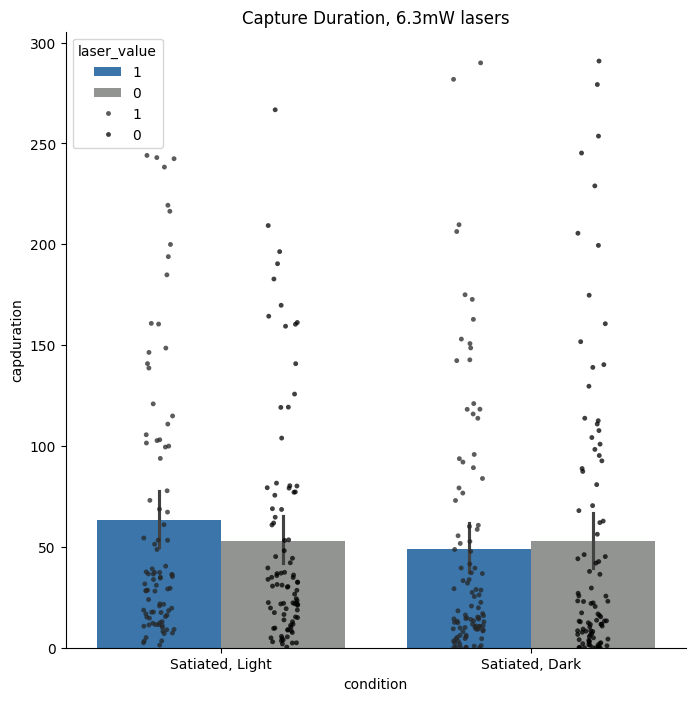

In [17]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

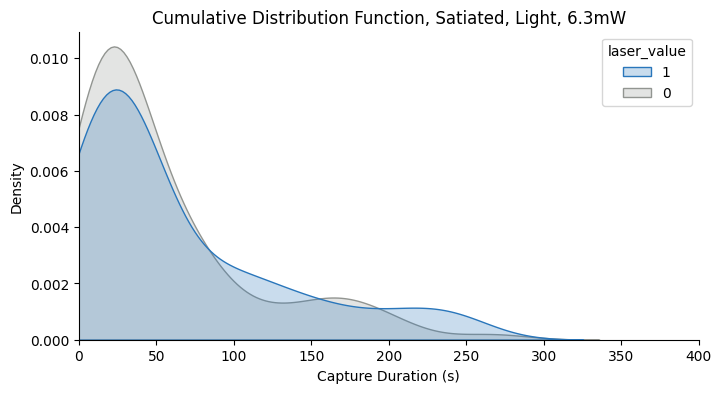

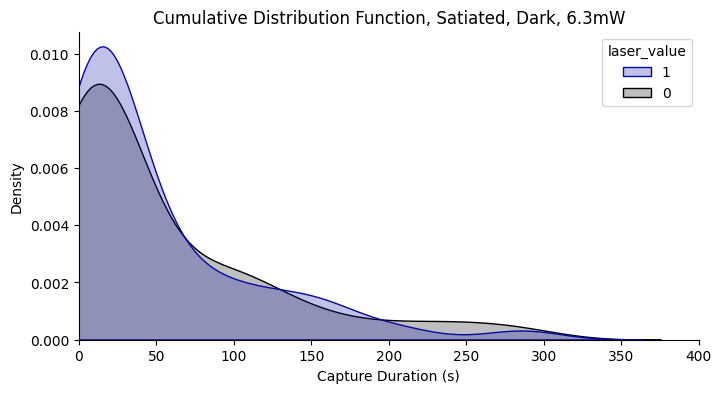

In [18]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='1.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 400)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='2.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 400)
# plt.ylim(0, 0.06)
sns.despine()

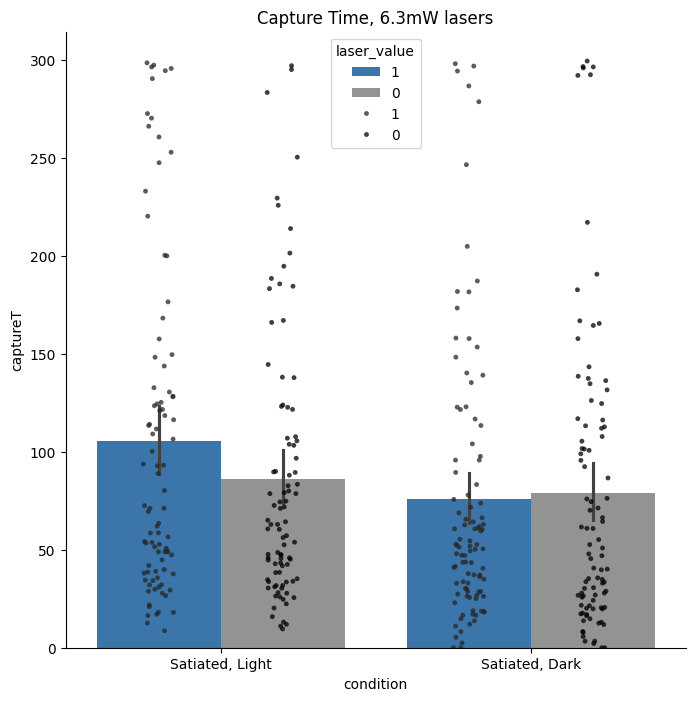

In [16]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Time, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

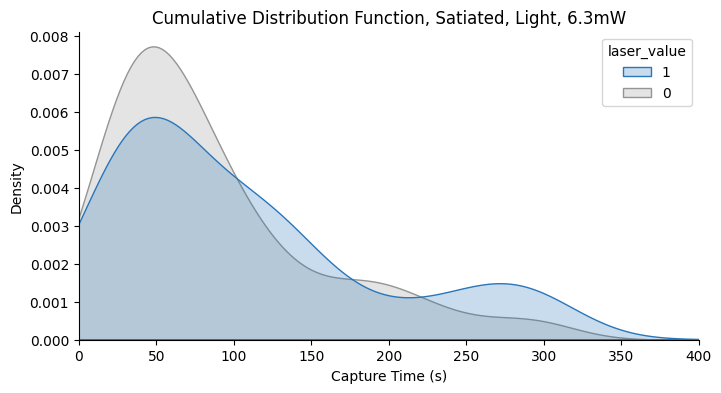

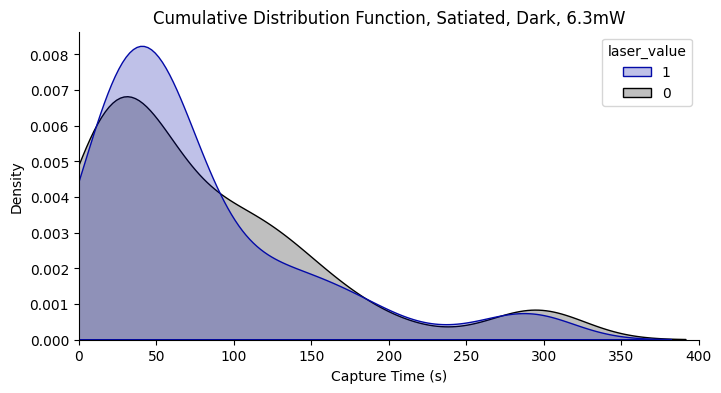

In [20]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='1.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 400)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='2.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 400)
# plt.ylim(0, 0.06)
sns.despine()

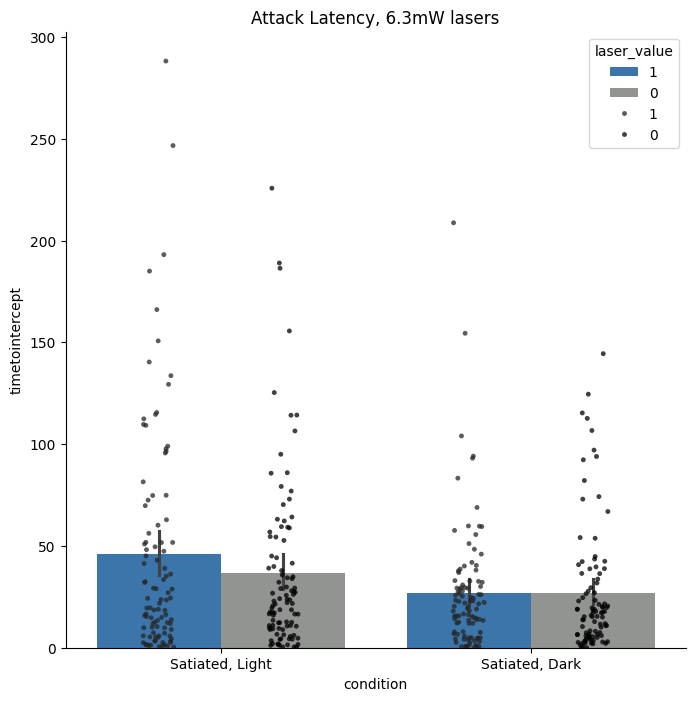

In [14]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='timetointercept', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='timetointercept', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Attack Latency, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

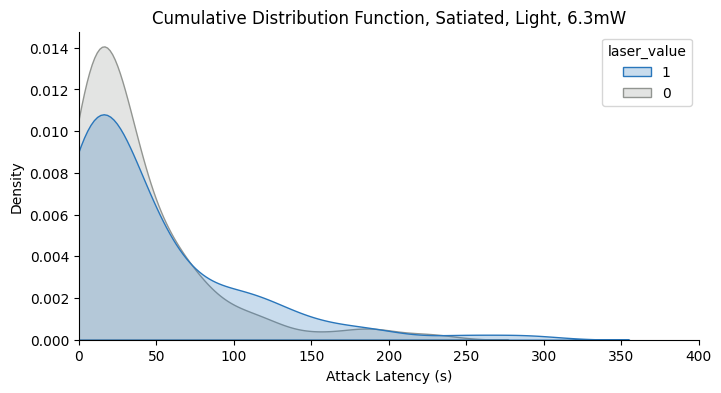

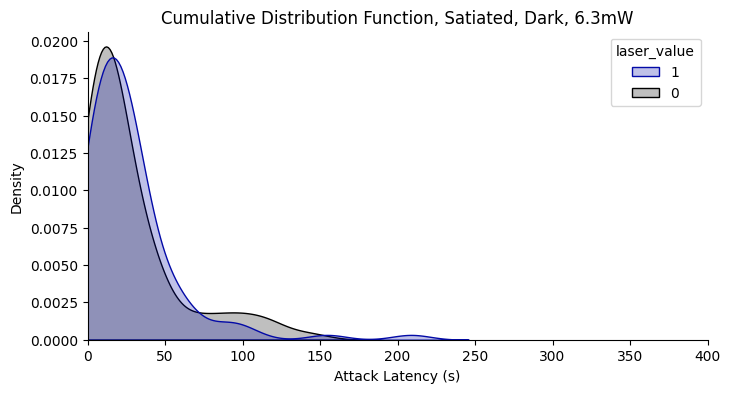

In [21]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='1.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 400)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='2.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 400)
# plt.ylim(0, 0.06)
sns.despine()

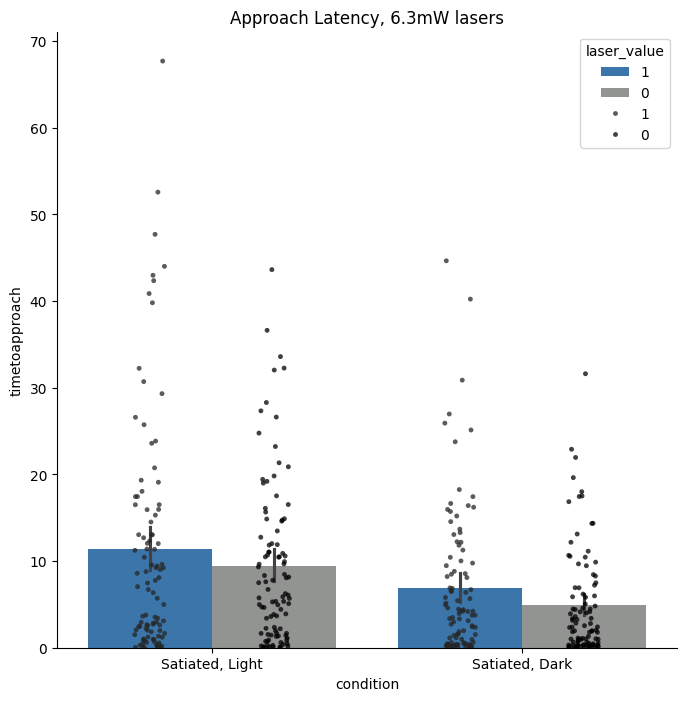

In [15]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='timetoapproach', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='timetoapproach', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Approach Latency, 6.3mW lasers')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

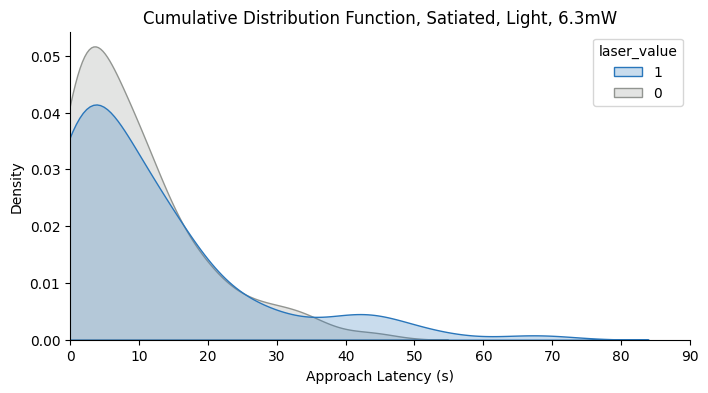

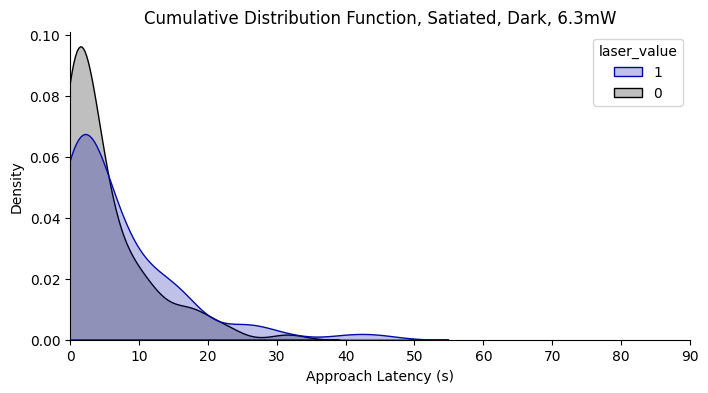

In [24]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='1.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, 6.3mW')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 90)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='2.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, 6.3mW')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 90)
# plt.ylim(0, 0.06)
sns.despine()

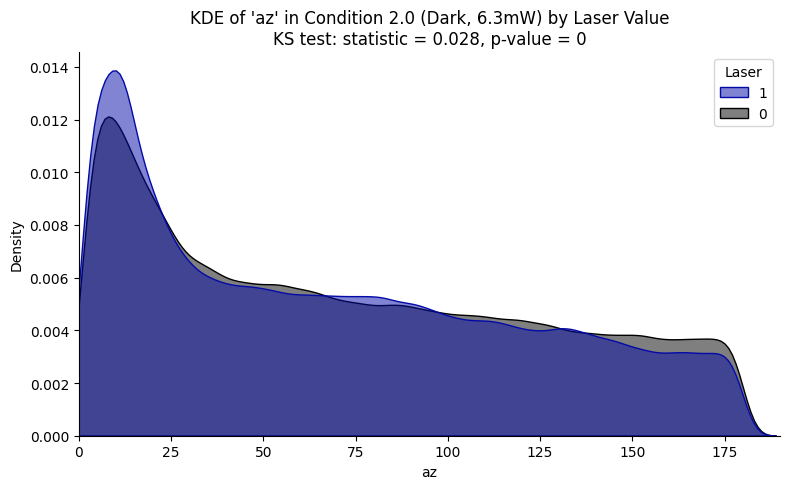

In [28]:

from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


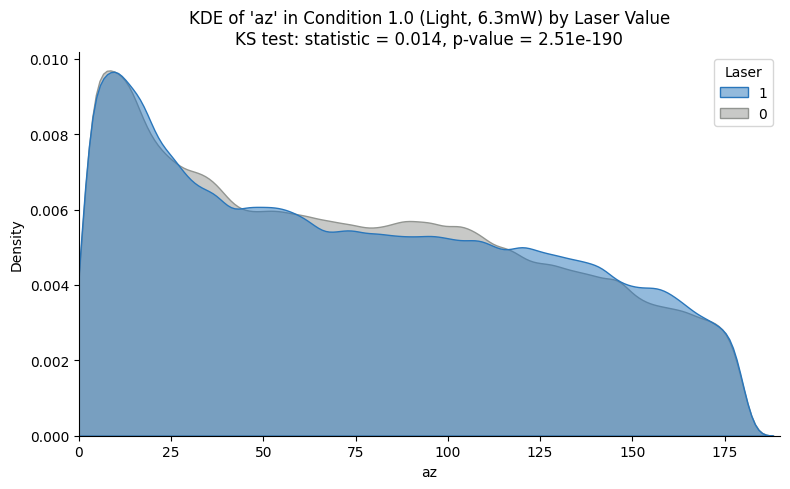

In [27]:

from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


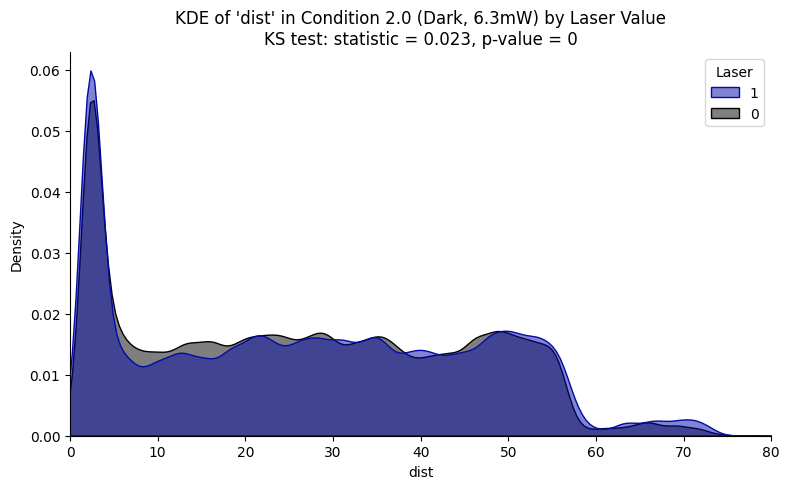

In [31]:

from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,80)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()


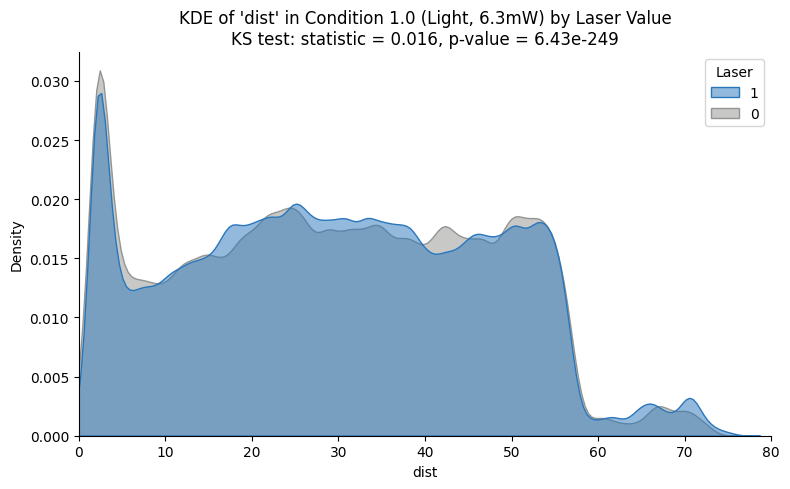

In [32]:

from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, 6.3mW) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,80)
# plt.ylim(0,0.012)
plt.tight_layout()
sns.despine()
plt.show()
